In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [3]:
%pip install kagglehub

import kagglehub

Note: you may need to restart the kernel to use updated packages.


In [4]:
df = pd.read_csv("C:\\Users\\NocTo\\OneDrive\\Ambiente de Trabalho\\amz_uk_price_prediction_dataset.csv")

In [5]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [6]:
# Part 1
#1
crosstab = pd.crosstab(df['category'], df['isBestSeller'])
crosstab

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [7]:
# I had crosstab[True] / crosstab[False] but thats the ratio of bestsellers to non-bestsellers, not the proportion
# True / False = 0.111 → not directly interpretable as “fraction of products that are bestsellers”
# True / (True + False) = 10 / 100 = 0.1 → directly tells you 10% of products are bestsellers
crosstab['bestseller_proportion'] = crosstab[True] / (crosstab[True] + crosstab[False])

crosstab_sorted = crosstab.sort_values(by = 'bestseller_proportion', ascending = False)
crosstab_sorted

isBestSeller,False,True,bestseller_proportion
category,,,
Grocery,9008,556,0.058135
Smart Home Security & Lighting,98,6,0.057692
Health & Personal Care,9017,552,0.057686
Mobile Phone Accessories,248,11,0.042471
Power & Hand Tools,8353,306,0.035339
...,...,...,...
Bedding Collections,6309,0,0.000000
CPUs,249,0,0.000000
"CD, Disc & Tape Players",8798,0,0.000000


In [8]:
# No, there aren't categories where being a best-seller is more prevalent

In [9]:
#2
new_cross = pd.crosstab(df['category'], df['isBestSeller'])

from scipy.stats import chi2_contingency

_, chi2_p_value, _, _ = chi2_contingency(new_cross)
chi2_p_value

np.float64(0.0)

In [10]:
# Since p-value < 0.05, this suggests that there is a significant association between the category and isBestSeller variables

In [11]:
from scipy.stats.contingency import association

association(new_cross, method="cramer")

0.1222829439760564

In [12]:
# Since 0 indicates no association, and 1 represents a perfect association between the variables, the result of 0.122 suggests a weak association between category and isBestSeller.

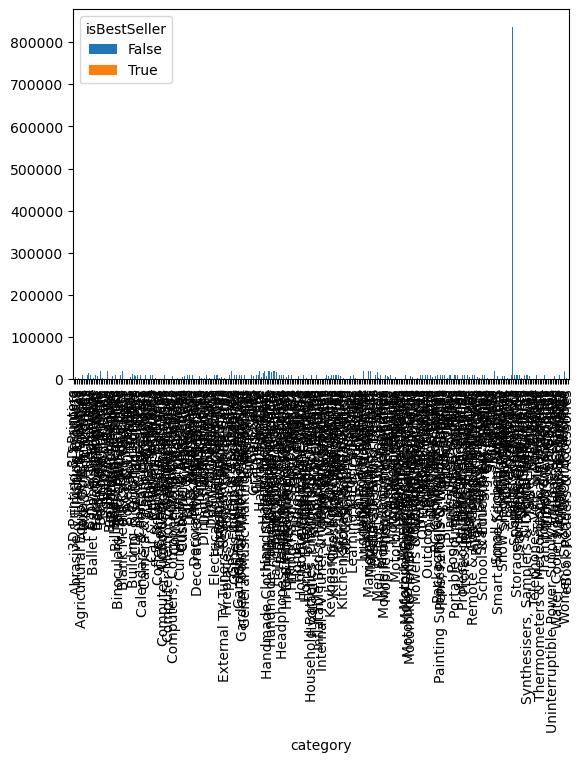

In [13]:
#3
new_cross.plot(kind="bar", stacked=True)
plt.show()

In [14]:
#Part 2
#1

Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

df = df[(df['price'] >= Q1 - 1.5 * IQR) & (df['price'] <= Q3 + 1.5 * IQR)]

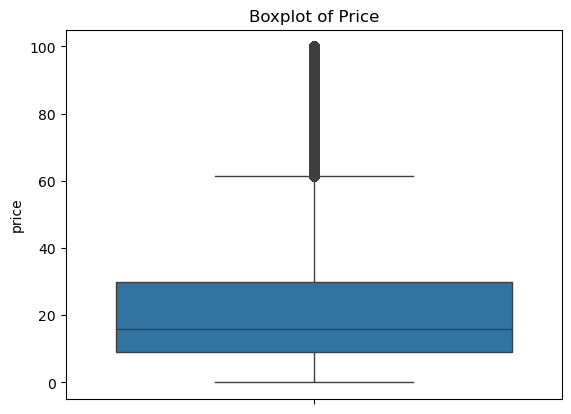

In [15]:
sns.boxplot(df['price'])
plt.title('Boxplot of Price')
plt.show()

In [16]:
category_counts = df.groupby('category').size()
category_counts = category_counts.sort_values(ascending = False) 
top_20_categories = category_counts.head(20).index

df_top = df[df['category'].isin(top_20_categories)]
df_top.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
19513,21072,B09477KHQ3,"Personalised Birthday Print Gift ""THE YEAR YOU...",4.5,763,7.99,False,900,Handmade Home & Kitchen Products
19514,21073,B0BSRFQYG8,Wax Melts 4 Bars | Build Your Own Box (Choose ...,3.9,117,6.49,True,800,Handmade Home & Kitchen Products
19515,21074,B09N9GVHV9,"Personalised Birthday Print Gift ""ON THE DAY/Y...",4.6,1155,8.99,True,600,Handmade Home & Kitchen Products
19516,21075,B0BRYGV7PQ,Fresh Wax Melts - Laundry Type Wax Melts - Str...,4.5,56,4.99,True,500,Handmade Home & Kitchen Products
19517,21076,B0B1JHB28R,Manta Makes Work Leaving Gifts | I Used to Wor...,4.7,261,9.95,True,400,Handmade Home & Kitchen Products


C:\Users\NocTo\AppData\Local\Temp\ipykernel_11928\25924529.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data = df_top, x = 'price', y = 'category', palette='coolwarm')


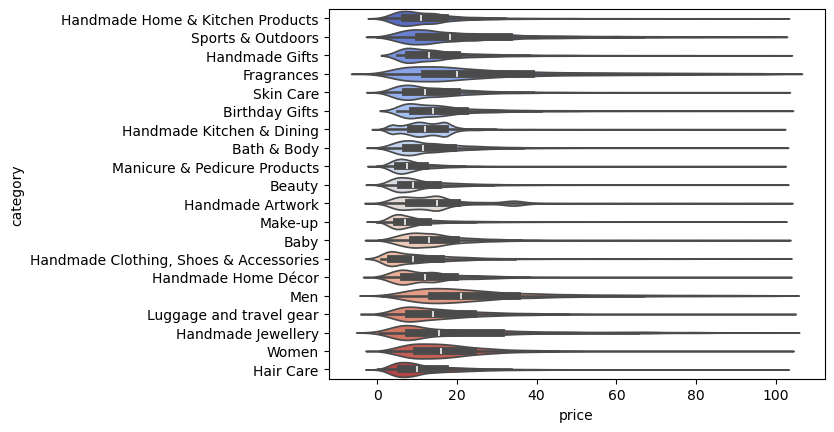

In [17]:
sns.violinplot(data = df_top, x = 'price', y = 'category', palette='coolwarm')
plt.show()

In [18]:
median_prices = df.groupby('category')['price'].median()


highest_median_category = median_prices.idxmax()
highest_median_category

'Desktop PCs'

C:\Users\NocTo\AppData\Local\Temp\ipykernel_11928\900452648.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x = avg_prices.values, y = avg_prices.index, palette = "viridis")


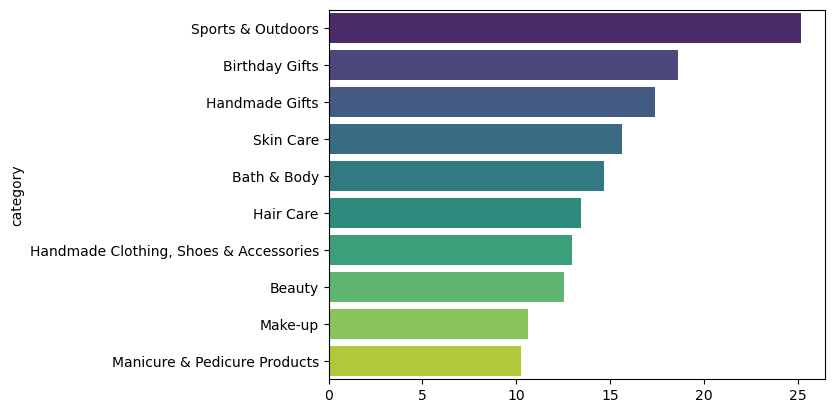

In [19]:
#2
category_counts = df.groupby('category').size()
category_counts = category_counts.sort_values(ascending = False) 
top_10_categories = category_counts.head(10).index

df_top_10 = df[df['category'].isin(top_10_categories)]

avg_prices = df_top_10.groupby('category')['price'].mean().sort_values(ascending = False)

sns.barplot(x = avg_prices.values, y = avg_prices.index, palette = "viridis")
plt.show()

In [20]:
avg_prices = df.groupby('category')['price'].mean()

highest_avg_category = avg_prices.idxmax()
highest_avg_category

'Motherboards'

C:\Users\NocTo\AppData\Local\Temp\ipykernel_11928\2295505745.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data = df_top_10, x = 'stars', y = 'category', palette = "coolwarm")


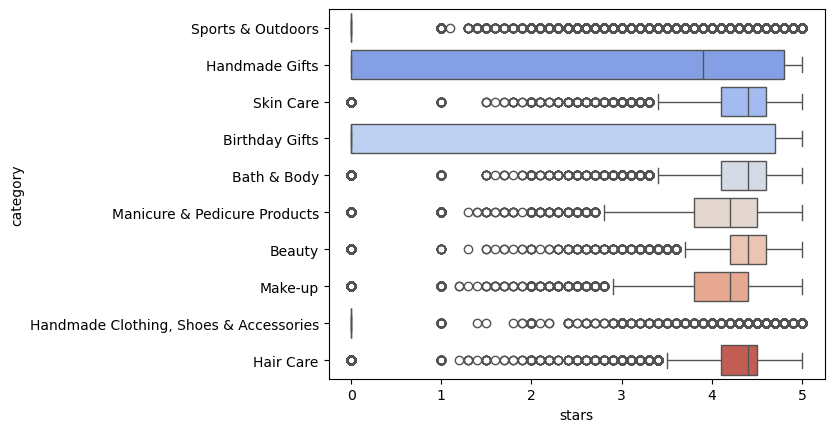

In [21]:
#3
category_counts = df.groupby('category').size()
category_counts = category_counts.sort_values(ascending = False) 
top_10_categories = category_counts.head(10).index

df_top_10 = df[df['category'].isin(top_10_categories)]

sns.boxplot(data = df_top_10, x = 'stars', y = 'category', palette = "coolwarm")
plt.show()


In [22]:
median_ratiing = df.groupby('category')['stars'].median()

highest_median_ratiing = median_ratiing.idxmax()
highest_median_ratiing

'Computer Memory'

In [23]:
#Part 3
1
correlation_pearson = df['price'].corr(df['stars'])

correlation_spearman = df['price'].corr(df['stars'], method='spearman')

correlation_pearson, correlation_spearman

(np.float64(-0.0776729987818137), np.float64(-0.06679697280768314))

In [24]:
#A correlation of -0.077 is actually very weak, almost negligible.
#Similarly, Spearman correlation of -0.066 is also very weak.
#This means there is essentially no meaningful correlation between price and star rating.
#Both correlations are close to 0. Price and rating do not move together in any strong pattern.

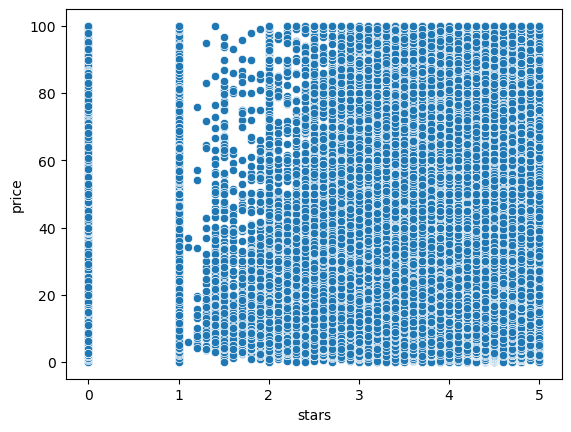

In [25]:
#2
sns.scatterplot(data = df, x = 'stars', y = 'price')
plt.show()

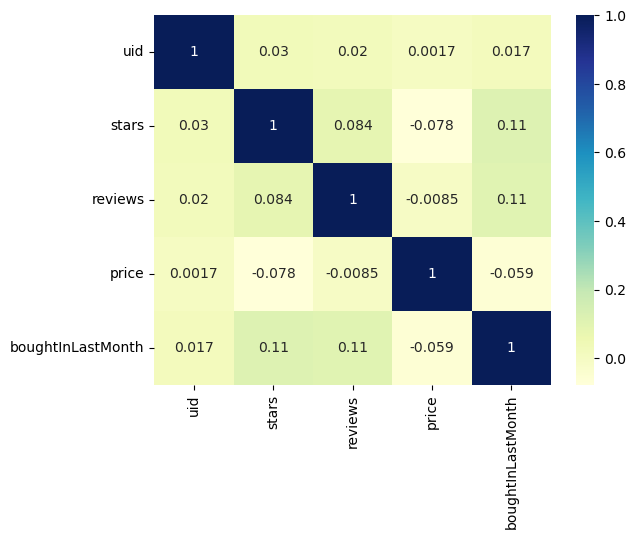

In [26]:
numerical_vars = df.select_dtypes(include=np.number)

# I didnt use the numerical_vars.corr() to get the correlation coefficients first - numerical_vars is just the raw data
corr_matrix = numerical_vars.corr()

sns.heatmap(corr_matrix, cmap="YlGnBu", annot=True)
plt.show()

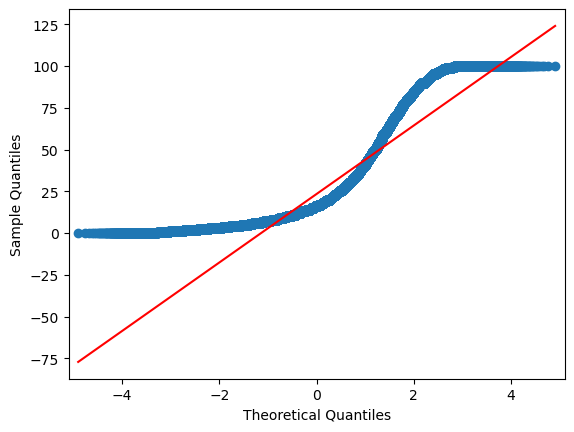

In [ ]:
import statsmodels.api as sm

sm.qqplot(df['price'], line = 's')

In [ ]:
#The QQ plot indicates price is right skewed with heavy tails, especially on the upper end — price is not normally distributed

In [ ]:
#skew direction:

#if your points bend upward / are above the line in the right tail → that means your actual high values are higher than normal → right skew

#if they bend below the line in the right tail → left skew

#in your plot the far right side curves sharply above → therefore right skew.

#heavy tails / fat tails evaluation:

#if both tails deviate away from the line strongly → fat tails.
#yours lower left tail is also above → not as crazy as upper but it still deviates → heavier / not normal.

#normal distribution tails stick to the line much closer.

#central body normality evaluation:

#if it was normal → the middle points lie straight on the red line.
#yours bow away / curve → not normal.